In [ ]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.20.0
GPU: []


In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
import zipfile
import requests

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

import seaborn as sns

In [ ]:
url = "https://www.kaggle.com/api/v1/datasets/download/kaustubhb999/tomatoleaf"

response = requests.get(url)

print("Status code:", response.status_code)

with open("/content/tomatoleaf.zip", "wb") as f:
    f.write(response.content)

print("Dataset downloaded successfully!")

file_size = os.path.getsize("/content/tomatoleaf.zip") / (1024 * 1024)

print("File size:", round(file_size, 2), "MB")

Status code: 200
Dataset downloaded successfully!
File size: 178.87 MB


In [ ]:
dataset_path = "/content/tomato_dataset"

os.makedirs(dataset_path, exist_ok=True)

with zipfile.ZipFile(
    "/content/tomatoleaf.zip",
    "r"
) as zip_ref:

    zip_ref.extractall(dataset_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
for root, dirs, files in os.walk(dataset_path):

    level = root.replace(
        dataset_path, ""
    ).count(os.sep)

    if level <= 2:

        print(
            "  " * level +
            os.path.basename(root) +
            "/"
        )

tomato_dataset/
  tomato/
    train/
    val/
  train/
    early_blight/
    bacterial_spot/
    yellow_leaf_curl_virus/
    septoria_leaf_spot/
    healthy/
    twospotted_spider_mite/
    leaf_mold/
    late_blight/
    target_spot/
    mosaic_virus/
  test/
    early_blight/
    bacterial_spot/
    yellow_leaf_curl_virus/
    septoria_leaf_spot/
    healthy/
    twospotted_spider_mite/
    leaf_mold/
    late_blight/
    target_spot/
    mosaic_virus/


In [ ]:
image_extensions = (
    ".jpg",
    ".jpeg",
    ".png"
)

image_folders = []

for root, dirs, files in os.walk(dataset_path):

    image_count = sum(
        file.lower().endswith(image_extensions)
        for file in files
    )

    if image_count > 0:

        image_folders.append(
            (root, image_count)
        )

for folder, count in image_folders:

    print(
        folder,
        "->",
        count,
        "images"
    )

/content/tomato_dataset/tomato/train/Tomato___Septoria_leaf_spot -> 1000 images
/content/tomato_dataset/tomato/train/Tomato___Leaf_Mold -> 1000 images
/content/tomato_dataset/tomato/train/Tomato___Spider_mites Two-spotted_spider_mite -> 1000 images
/content/tomato_dataset/tomato/train/Tomato___healthy -> 1000 images
/content/tomato_dataset/tomato/train/Tomato___Late_blight -> 1000 images
/content/tomato_dataset/tomato/train/Tomato___Target_Spot -> 1000 images
/content/tomato_dataset/tomato/train/Tomato___Tomato_Yellow_Leaf_Curl_Virus -> 1000 images
/content/tomato_dataset/tomato/train/Tomato___Bacterial_spot -> 1000 images
/content/tomato_dataset/tomato/train/Tomato___Tomato_mosaic_virus -> 1000 images
/content/tomato_dataset/tomato/train/Tomato___Early_blight -> 1000 images
/content/tomato_dataset/tomato/val/Tomato___Septoria_leaf_spot -> 100 images
/content/tomato_dataset/tomato/val/Tomato___Leaf_Mold -> 100 images
/content/tomato_dataset/tomato/val/Tomato___Spider_mites Two-spotted_

In [ ]:
candidate_dirs = []

for root, dirs, files in os.walk(dataset_path):

    class_count = 0

    for directory in dirs:

        folder_path = os.path.join(
            root,
            directory
        )

        if not os.path.isdir(folder_path):
            continue

        image_count = sum(
            file.lower().endswith(image_extensions)
            for file in os.listdir(folder_path)
            if os.path.isfile(
                os.path.join(
                    folder_path,
                    file
                )
            )
        )

        if image_count > 0:

            class_count += 1

    if class_count >= 2:

        candidate_dirs.append(
            (root, class_count)
        )

print("Possible dataset directories:\n")

for path, count in candidate_dirs:

    print(
        path,
        "->",
        count,
        "classes"
    )

Possible dataset directories:

/content/tomato_dataset/tomato/train -> 10 classes
/content/tomato_dataset/tomato/val -> 10 classes
/content/tomato_dataset/train -> 10 classes
/content/tomato_dataset/test -> 10 classes


In [ ]:
DATASET_DIR = candidate_dirs[0][0]

print("Dataset directory:")
print(DATASET_DIR)

Dataset directory:
/content/tomato_dataset/tomato/train


In [ ]:
classes = sorted([
    folder
    for folder in os.listdir(DATASET_DIR)
    if os.path.isdir(
        os.path.join(
            DATASET_DIR,
            folder
        )
    )
])

print("Number of classes:", len(classes))

print("\nClasses:")

for i, class_name in enumerate(classes):

    print(
        i,
        ":",
        class_name
    )

Number of classes: 10

Classes:
0 : Tomato___Bacterial_spot
1 : Tomato___Early_blight
2 : Tomato___Late_blight
3 : Tomato___Leaf_Mold
4 : Tomato___Septoria_leaf_spot
5 : Tomato___Spider_mites Two-spotted_spider_mite
6 : Tomato___Target_Spot
7 : Tomato___Tomato_Yellow_Leaf_Curl_Virus
8 : Tomato___Tomato_mosaic_virus
9 : Tomato___healthy


In [ ]:
df = pd.DataFrame(
    list(class_counts.items()),
    columns=[
        "Disease",
        "Number of Images"
    ]
)

print(df)

  Disease  Number of Images
0    test                 0
1   train                 0


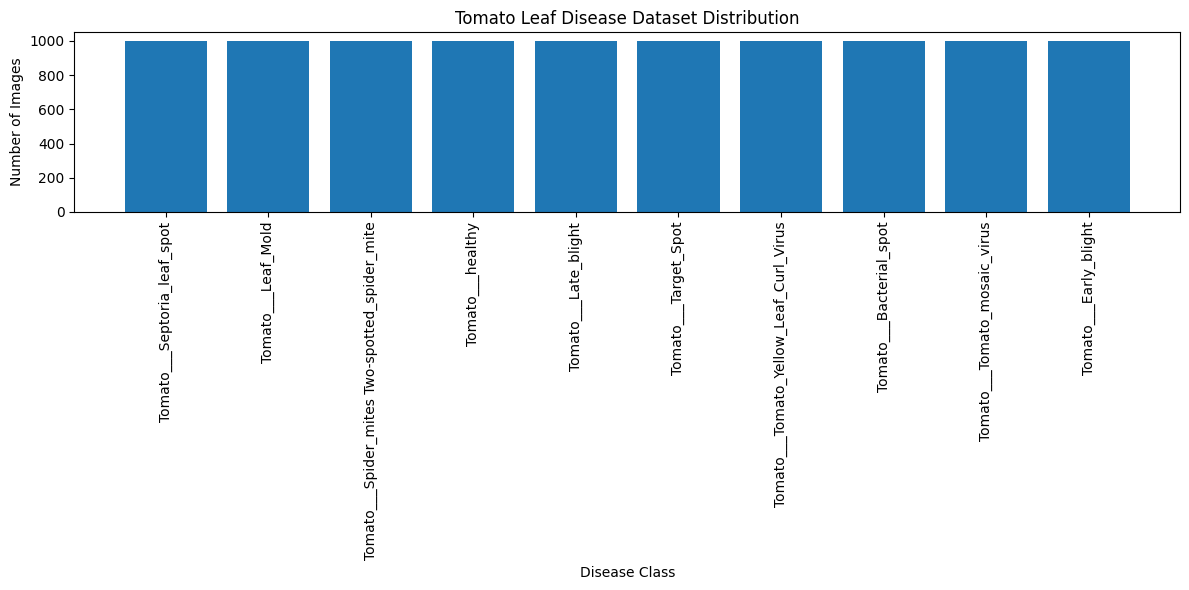

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    df["Disease"],
    df["Number of Images"]
)

plt.xlabel("Disease Class")
plt.ylabel("Number of Images")

plt.title(
    "Tomato Leaf Disease Dataset Distribution"
)

plt.xticks(
    rotation=90
)

plt.tight_layout()

plt.show()

In [ ]:
IMG_HEIGHT = 128
IMG_WIDTH = 128

BATCH_SIZE = 32

print("Image Height:", IMG_HEIGHT)
print("Image Width:", IMG_WIDTH)
print("Batch Size:", BATCH_SIZE)

Image Height: 128
Image Width: 128
Batch Size: 32


In [ ]:
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.20
)

In [ ]:
train_data = datagen.flow_from_directory(

    DATASET_DIR,

    target_size=(
        IMG_HEIGHT,
        IMG_WIDTH
    ),

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    subset="training",

    shuffle=True
)

Found 8000 images belonging to 10 classes.


In [ ]:
validation_data = datagen.flow_from_directory(

    DATASET_DIR,
    target_size=(
        IMG_HEIGHT,
        IMG_WIDTH
    ),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

Found 2000 images belonging to 10 classes.


In [ ]:
class_indices = train_data.class_indices
class_names = list(
    class_indices.keys()
)
num_classes = len(
    class_names
)
print(
    "Number of classes:",
    num_classes
)
print("\nClass Mapping:")
for class_name, index in class_indices.items():
    print(
        index,
        ":",
        class_name
    )

Number of classes: 10

Class Mapping:
0 : Tomato___Bacterial_spot
1 : Tomato___Early_blight
2 : Tomato___Late_blight
3 : Tomato___Leaf_Mold
4 : Tomato___Septoria_leaf_spot
5 : Tomato___Spider_mites Two-spotted_spider_mite
6 : Tomato___Target_Spot
7 : Tomato___Tomato_Yellow_Leaf_Curl_Virus
8 : Tomato___Tomato_mosaic_virus
9 : Tomato___healthy


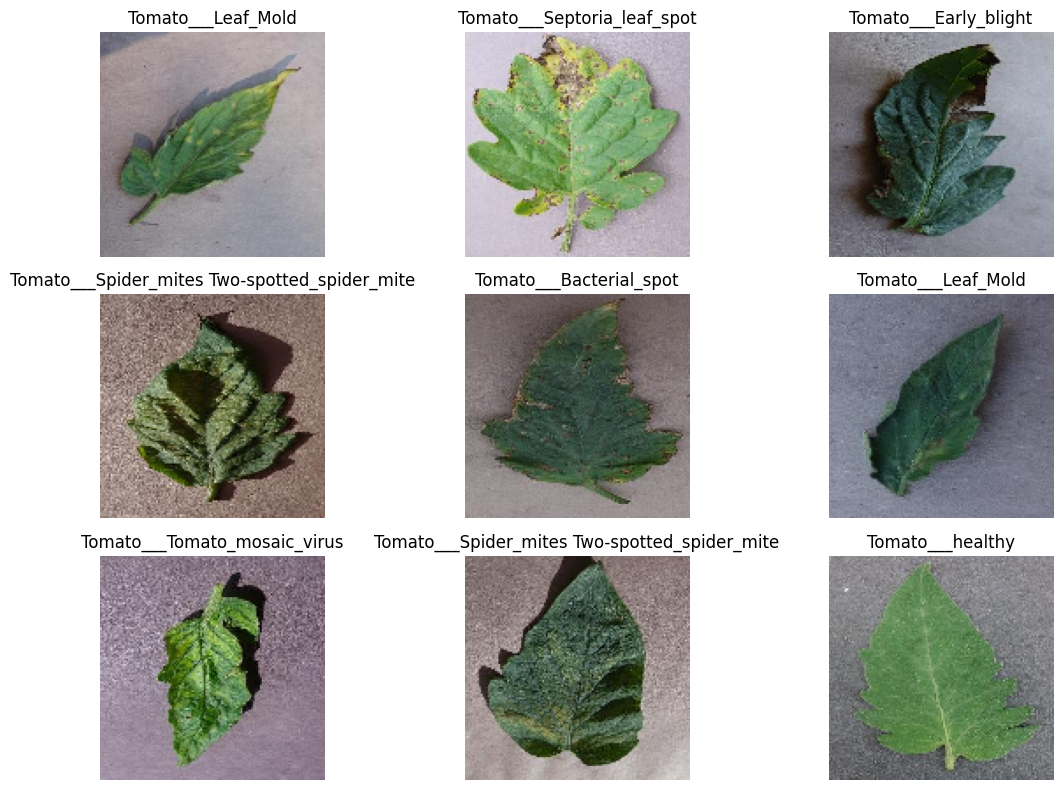

In [ ]:
images, labels = next(train_data)
plt.figure(figsize=(12, 8))
for i in range(9):
    plt.subplot(
        3,
        3,
        i + 1
    )
    plt.imshow(
        images[i]
    )
    class_index = np.argmax(
        labels[i]
    )
    plt.title(
        class_names[class_index]
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
model = Sequential([

    # Convolutional Layer 1
    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(
            IMG_HEIGHT,
            IMG_WIDTH,
            3
        )
    ),

    # Pooling Layer 1
    MaxPooling2D(
        pool_size=(2, 2)
    ),


    # Convolutional Layer 2
    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    # Pooling Layer 2
    MaxPooling2D(
        pool_size=(2, 2)
    ),


    # Convolutional Layer 3
    Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    # Pooling Layer 3
    MaxPooling2D(
        pool_size=(2, 2)
    ),


    # Convert feature maps into vector
    Flatten(),


    # Fully Connected Layer
    Dense(
        128,
        activation="relu"
    ),


    # Dropout
    Dropout(0.5),


    # Output Layer
    Dense(
        num_classes,
        activation="softmax"
    )

])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(

    optimizer="adam",

    loss="categorical_crossentropy",

    metrics=["accuracy"]
)

In [ ]:
EPOCHS = 5

history = model.fit(

    train_data,

    validation_data=validation_data,

    epochs=EPOCHS
)

Epoch 1/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 309s 1s/step - accuracy: 0.5173 - loss: 1.3855 - val_accuracy: 0.7400 - val_loss: 0.7919
Epoch 2/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 334s 1s/step - accuracy: 0.7145 - loss: 0.8168 - val_accuracy: 0.7950 - val_loss: 0.5782
Epoch 3/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 306s 1s/step - accuracy: 0.7713 - loss: 0.6640 - val_accuracy: 0.8615 - val_loss: 0.4216
Epoch 4/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 286s 1s/step - accuracy: 0.8067 - loss: 0.5420 - val_accuracy: 0.8710 - val_loss: 0.4187
Epoch 5/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 301s 1s/step - accuracy: 0.8406 - loss: 0.4646 - val_accuracy: 0.8990 - val_loss: 0.3223


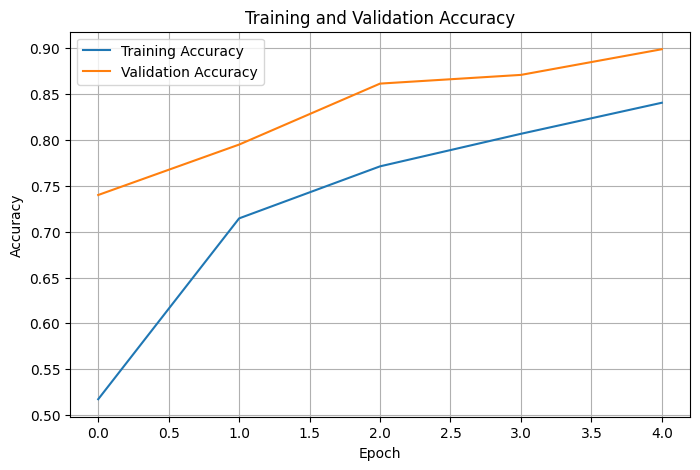

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "Training and Validation Accuracy"
)

plt.legend()

plt.grid()

plt.show()

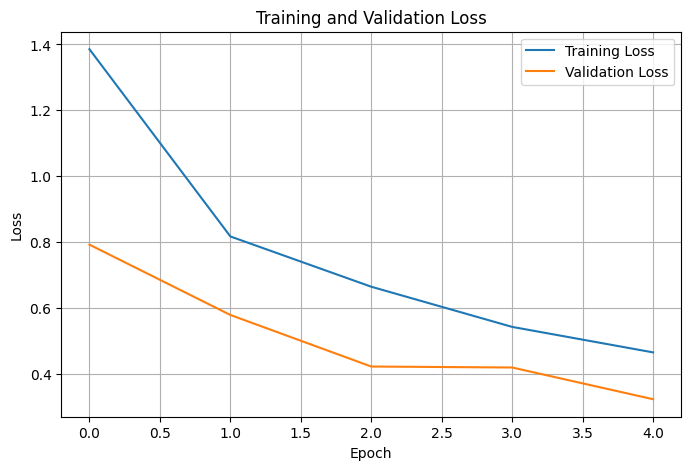

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Training and Validation Loss"
)

plt.legend()

plt.grid()

plt.show()

In [ ]:
validation_data.reset()

loss, accuracy = model.evaluate(
    validation_data
)

print(
    "Validation Loss:",
    round(loss, 4)
)

print(
    "Validation Accuracy:",
    round(
        accuracy * 100,
        2
    ),
    "%"
)

63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 339ms/step - accuracy: 0.8990 - loss: 0.3223
Validation Loss: 0.3223
Validation Accuracy: 89.9 %


In [ ]:
validation_data.reset()

predictions = model.predict(
    validation_data
)

predicted_classes = np.argmax(
    predictions,
    axis=1
)

true_classes = validation_data.classes

63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 319ms/step


In [ ]:
report = classification_report(

    true_classes,

    predicted_classes,

    target_names=class_names
)

print(report)

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.89      0.92      0.91       200
                        Tomato___Early_blight       0.78      0.82      0.80       200
                         Tomato___Late_blight       0.87      0.86      0.86       200
                           Tomato___Leaf_Mold       0.92      0.93      0.93       200
                  Tomato___Septoria_leaf_spot       0.92      0.80      0.86       200
Tomato___Spider_mites Two-spotted_spider_mite       0.87      0.93      0.90       200
                         Tomato___Target_Spot       0.86      0.92      0.89       200
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.95      0.91      0.93       200
                 Tomato___Tomato_mosaic_virus       0.95      0.97      0.96       200
                             Tomato___healthy       0.99      0.94      0.97       200

                                     accu

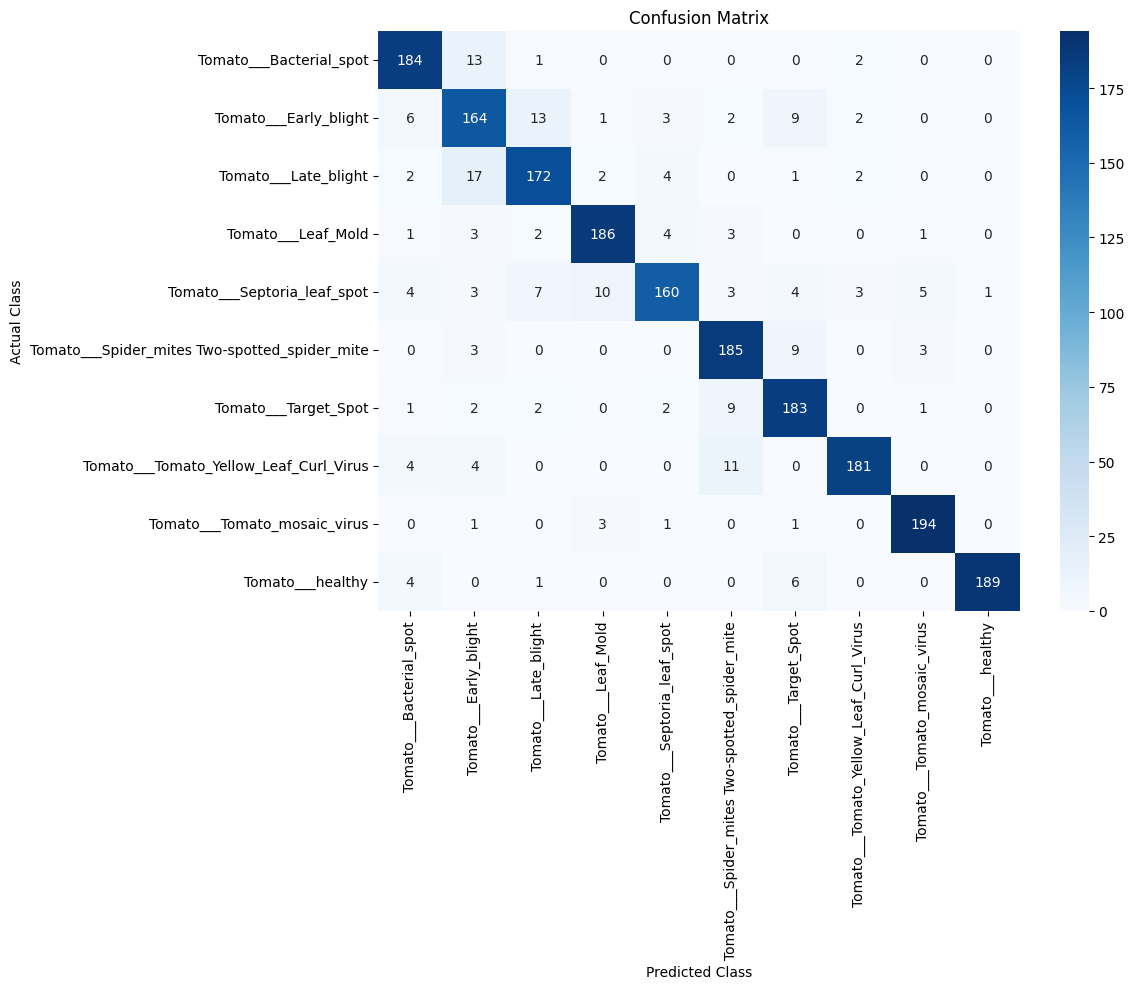

In [ ]:
cm = confusion_matrix(

    true_classes,

    predicted_classes
)

plt.figure(figsize=(12, 10))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=class_names,

    yticklabels=class_names
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.title(
    "Confusion Matrix"
)

plt.xticks(
    rotation=90
)

plt.yticks(
    rotation=0
)

plt.tight_layout()

plt.show()

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 3-CercosporaLeaf1.jpg to 3-CercosporaLeaf1.jpg


In [ ]:
img_path = list(
    uploaded.keys()
)[0]

img = image.load_img(

    img_path,

    target_size=(
        IMG_HEIGHT,
        IMG_WIDTH
    )
)

img_array = image.img_to_array(
    img
)

img_array = img_array / 255.0

img_array = np.expand_dims(
    img_array,
    axis=0
)

prediction = model.predict(
    img_array
)

predicted_index = np.argmax(
    prediction[0]
)

predicted_class = class_names[
    predicted_index
]

confidence = (
    prediction[0][predicted_index]
    * 100
)

print(
    "Predicted Disease:",
    predicted_class
)

print(
    "Confidence:",
    round(
        confidence,
        2
    ),
    "%"
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 452ms/step
Predicted Disease: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Confidence: 77.93 %


In [ ]:
probabilities = prediction[0]

results = pd.DataFrame({

    "Disease": class_names,

    "Probability": probabilities * 100

})

results = results.sort_values(
    "Probability",
    ascending=False
)

results

,Disease,Probability
7,Tomato___Tomato_Yellow_Leaf_Curl_Virus,7.793357e+01
2,Tomato___Late_blight,2.092340e+01
1,Tomato___Early_blight,1.103725e+00
0,Tomato___Bacterial_spot,2.254115e-02
3,Tomato___Leaf_Mold,1.087265e-02
5,Tomato___Spider_mites Two-spotted_spider_mite,4.636978e-03
4,Tomato___Septoria_leaf_spot,1.032889e-03
6,Tomato___Target_Spot,2.168921e-04
9,Tomato___healthy,3.368351e-07
8,Tomato___Tomato_mosaic_virus,8.961730e-08


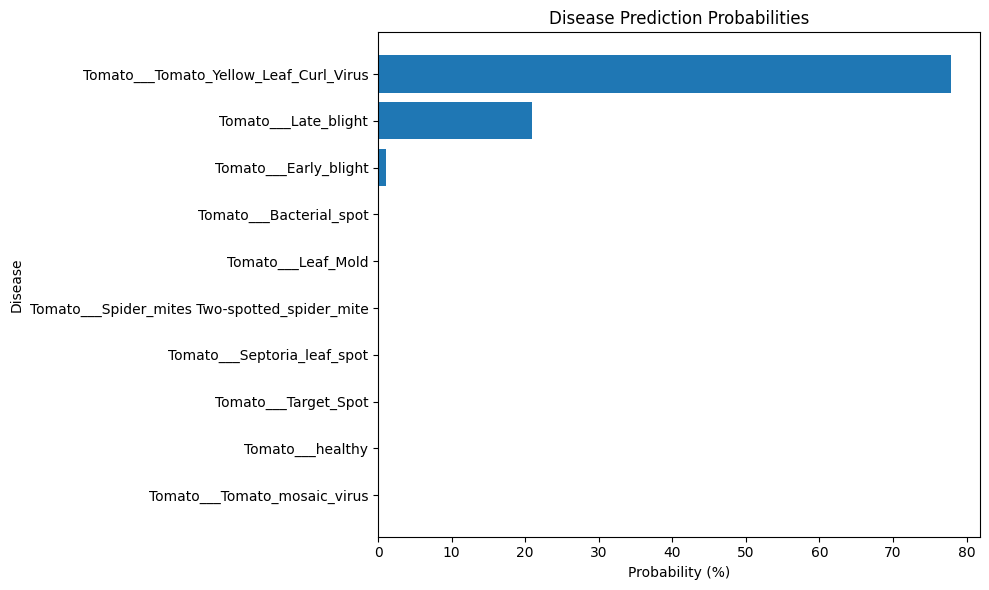

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    results["Disease"],
    results["Probability"]
)

plt.xlabel(
    "Probability (%)"
)

plt.ylabel(
    "Disease"
)

plt.title(
    "Disease Prediction Probabilities"
)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

In [ ]:
model.save(
    "/content/tomato_disease_cnn.keras"
)

print(
    "Model saved successfully!"
)

Model saved successfully!


In [ ]:
files.download(
    "/content/tomato_disease_cnn.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>